In [1]:
#!/usr/bin/env python3
"""
Explainable GeoAI for urban Land Surface Temperature (LST)
==========================================================

Gradient Boosting regression of LST on urban form and land-cover predictors,
explained with SHAP (TreeExplainer), with per-cell and neighbourhood-scale
SHAP attribution maps.

Pipeline
--------
1. Load a gridded cell table (one row per grid cell), or build a synthetic
   demo city when no data file is given.
2. Fit a GradientBoostingRegressor. Evaluate it on a random hold-out set and
   with spatial block cross-validation (neighbourhoods as CV groups), since
   random splits overstate accuracy on spatially autocorrelated data.
3. Compute exact tree SHAP values for every land cell.
4. Map SHAP values for the key drivers (distance to water, green space area,
   NDVI), aggregate them to neighbourhoods, and test their spatial structure
   with global Moran's I.

Input table (--data)
--------------------
CSV, one row per cell of a regular grid, with columns:
    x, y              cell centre in a projected CRS (metres)
    lst               land surface temperature (deg C)
    dist_water_m      distance to the nearest water body (m)
    green_area_ha     green space area within 300 m of the cell (ha)
    ndvi              mean NDVI of the cell
    impervious_frac   impervious surface fraction (0-1)
    bldg_height_m     mean building height (m)
optional:
    neighborhood      neighbourhood / block-group ID used for aggregation
    is_water          1 for water cells (drawn on maps, excluded from model)

Without --data the script runs on a SYNTHETIC city whose LST comes from a
known generating equation (see make_synthetic_city). Results in that mode
test the pipeline only; they are not empirical findings.

Usage
-----
    python lst_shap_prototype.py
    python lst_shap_prototype.py --data data/cells_100m.csv --out outputs --tune

Requirements: numpy, pandas, scipy, scikit-learn, shap, matplotlib
"""

from __future__ import annotations

import argparse
import json
import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from scipy import ndimage
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict, train_test_split

# --------------------------------------------------------------------------- #
# Configuration
# --------------------------------------------------------------------------- #
TARGET = "lst"
FEATURES = ["dist_water_m", "green_area_ha", "ndvi", "impervious_frac", "bldg_height_m"]
KEY_FEATURES = ["dist_water_m", "green_area_ha", "ndvi"]  # drivers mapped in detail

LABELS = {
    "lst": "LST (°C)",
    "dist_water_m": "Distance to water (m)",
    "green_area_ha": "Green space within 300 m (ha)",
    "ndvi": "NDVI",
    "impervious_frac": "Impervious fraction",
    "bldg_height_m": "Building height (m)",
}
SHORT = {
    "dist_water_m": "Distance to water",
    "green_area_ha": "Green space area",
    "ndvi": "NDVI",
    "impervious_frac": "Impervious surface",
    "bldg_height_m": "Building height",
}


@dataclass
class Config:
    seed: int = 42
    grid_n: int = 80                 # synthetic grid is grid_n x grid_n cells
    cell_m: float = 75.0             # synthetic cell size (m)
    green_radius_m: float = 300.0    # buffer for green space area
    block_m: float = 750.0           # neighbourhood block size if no IDs are given
    test_size: float = 0.25
    cv_folds: int = 5
    n_permutations: int = 199        # Moran's I pseudo p-value
    gbr_params: dict = field(default_factory=lambda: dict(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        min_samples_leaf=15,
        subsample=0.8,
        random_state=42,
    ))


# Colours: sequential = one hue light->dark; diverging = blue/red with grey midpoint.
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRIDLINE, SURFACE, WATER = "#e1e0d9", "#fcfcfb", "#a9a8a2"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
SEQ_HEAT = LinearSegmentedColormap.from_list(
    "seq_heat", ["#fde4d6", "#f6a985", "#eb6834", "#b8421b", "#6e260e"])
SEQ_POINTS = LinearSegmentedColormap.from_list(
    "seq_points", ["#b7d3f6", "#5598e7", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list(
    "div_cool_warm", ["#0d366b", "#2a78d6", "#9ec5f4", "#f0efec", "#f4b1b0", "#e34948", "#8f1d1d"])
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]   # one slot per key feature
OTHER = "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
})


def log(msg: str) -> None:
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


# --------------------------------------------------------------------------- #
# Data
# --------------------------------------------------------------------------- #
def _smooth_noise(rng: np.random.Generator, shape: tuple, sigma: float) -> np.ndarray:
    """Spatially autocorrelated standard-normal field."""
    z = ndimage.gaussian_filter(rng.standard_normal(shape), sigma)
    return (z - z.mean()) / z.std()


def make_synthetic_city(cfg: Config) -> tuple[pd.DataFrame, float]:
    """Build a synthetic gridded city with a river, a lake, parks and two urban cores.

    LST is generated from a known equation with non-linear cooling from water
    and green space, an NDVI effect, an impervious-surface effect and a
    water x imperviousness interaction, plus correlated and white noise.
    """
    rng = np.random.default_rng(cfg.seed)
    n, c = cfg.grid_n, cfg.cell_m
    L = n * c
    cols, rows = np.meshgrid(np.arange(n), np.arange(n))
    X = (cols + 0.5) * c
    Y = (n - rows - 0.5) * c

    def blob(cx, cy, r):
        return np.exp(-((X - cx) ** 2 + (Y - cy) ** 2) / (2 * r ** 2))

    # Water: meandering river + lake
    river_y = 0.40 * L + 0.09 * L * np.sin(X / (0.17 * L)) + 0.025 * L * np.sin(X / (0.045 * L))
    water = np.abs(Y - river_y) < 1.3 * c
    water |= ((X - 0.80 * L) / (0.075 * L)) ** 2 + ((Y - 0.82 * L) / (0.05 * L)) ** 2 < 1
    dist_water = ndimage.distance_transform_edt(~water) * c

    # Urban form: CBD + secondary (industrial) centre, scattered parks, riparian green
    core = np.clip(blob(0.52 * L, 0.62 * L, 0.20 * L) + 0.65 * blob(0.22 * L, 0.20 * L, 0.11 * L), 0, 1)
    parks = np.zeros_like(X)
    for _ in range(10):
        cx, cy = rng.uniform(0.05, 0.95, 2) * L
        parks += blob(cx, cy, rng.uniform(1.5, 4.5) * c)
    parks = np.clip(parks, 0, 1)
    riparian = 0.55 * np.exp(-dist_water / (2.5 * c))

    imperv = 0.12 + 0.80 * core + 0.07 * _smooth_noise(rng, X.shape, 3)
    imperv = np.clip(imperv * (1 - 0.85 * parks) * (1 - 0.6 * riparian), 0.02, 0.97)
    green = np.clip(0.75 * (1 - imperv) + 0.5 * parks + 0.3 * riparian
                    + 0.05 * _smooth_noise(rng, X.shape, 2), 0, 1)
    green[water] = 0.0
    ndvi = np.clip(0.03 + 0.78 * green + 0.035 * rng.standard_normal(X.shape), -0.05, 0.9)

    r_px = cfg.green_radius_m / c
    k = int(np.ceil(r_px))
    yy, xx = np.mgrid[-k:k + 1, -k:k + 1]
    kernel = (xx ** 2 + yy ** 2 <= r_px ** 2).astype(float)
    green_area_ha = ndimage.convolve(green, kernel, mode="reflect") * c * c / 1e4

    bldg_h = np.clip(3 + 40 * core ** 1.8 * imperv + 2.0 * np.abs(rng.standard_normal(X.shape)), 2, 70)

    # Generating equation for LST (deg C)
    lst = (31.0
           + 7.0 * imperv
           - 8.5 * (ndvi - 0.35)
           - 4.5 * np.exp(-dist_water / 350.0) * (1 - 0.4 * imperv)
           - 3.0 * (1 - np.exp(-green_area_ha / 12.0))
           - 0.03 * bldg_h * imperv
           + 0.8 * _smooth_noise(rng, X.shape, 5)
           + 0.5 * rng.standard_normal(X.shape))

    x0, y0 = 500_000.0, 4_300_000.0  # arbitrary projected origin (m)
    df = pd.DataFrame({
        "row": rows.ravel(), "col": cols.ravel(),
        "x": x0 + X.ravel(), "y": y0 + Y.ravel(),
        "is_water": water.ravel(),
        "dist_water_m": dist_water.ravel(),
        "green_area_ha": green_area_ha.ravel(),
        "ndvi": ndvi.ravel(),
        "impervious_frac": imperv.ravel(),
        "bldg_height_m": bldg_h.ravel(),
        TARGET: lst.ravel(),
    })
    return df, c


def load_cell_table(path: Path) -> tuple[pd.DataFrame, float]:
    """Read a gridded cell table and recover row/col indices from x/y."""
    df = pd.read_csv(path)
    missing = {"x", "y", TARGET, *FEATURES} - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")
    df["is_water"] = df.get("is_water", 0).astype(bool)
    xs = np.sort(df["x"].unique())
    cell = float(np.median(np.diff(xs)))
    df["col"] = np.rint((df["x"] - df["x"].min()) / cell).astype(int)
    df["row"] = np.rint((df["y"].max() - df["y"]) / cell).astype(int)
    return df, cell


def assign_neighborhoods(df: pd.DataFrame, block_m: float) -> pd.DataFrame:
    """Use supplied neighbourhood IDs, or fall back to square blocks of block_m."""
    if "neighborhood" in df.columns:
        df["neighborhood"] = df["neighborhood"].astype(str)
        return df
    bx = ((df["x"] - df["x"].min()) // block_m).astype(int)
    by = ((df["y"].max() - df["y"]) // block_m).astype(int)
    df["neighborhood"] = "NB-" + by.map("{:02d}".format) + "-" + bx.map("{:02d}".format)
    return df


def to_grid(rows: np.ndarray, cols: np.ndarray, values: np.ndarray, shape: tuple) -> np.ndarray:
    g = np.full(shape, np.nan)
    g[rows, cols] = values
    return g


# --------------------------------------------------------------------------- #
# Modelling
# --------------------------------------------------------------------------- #
def tune_hyperparameters(X: pd.DataFrame, y: pd.Series, groups: pd.Series, cfg: Config) -> dict:
    """Small grid search with spatial (grouped) folds."""
    grid = {"max_depth": [3, 4, 5], "learning_rate": [0.03, 0.05, 0.1], "min_samples_leaf": [10, 25]}
    base = {k: v for k, v in cfg.gbr_params.items() if k not in grid}
    search = GridSearchCV(GradientBoostingRegressor(**base), grid,
                          cv=GroupKFold(n_splits=3), scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y, groups=groups)
    log(f"  best params {search.best_params_}  (spatial-CV RMSE {-search.best_score_:.2f} °C)")
    return {**base, **search.best_params_}


def metrics(y_true, y_pred) -> dict:
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
    }


def fit_and_evaluate(land: pd.DataFrame, cfg: Config, tune: bool):
    X, y, groups = land[FEATURES], land[TARGET], land["neighborhood"]
    X_tr, X_te, y_tr, y_te, g_tr, _ = train_test_split(
        X, y, groups, test_size=cfg.test_size, random_state=cfg.seed)

    params = tune_hyperparameters(X_tr, y_tr, g_tr, cfg) if tune else dict(cfg.gbr_params)
    model = GradientBoostingRegressor(**params).fit(X_tr, y_tr)

    results = {
        "params": params,
        "n_train": int(len(X_tr)), "n_test": int(len(X_te)),
        "train": metrics(y_tr, model.predict(X_tr)),
        "test_random": metrics(y_te, model.predict(X_te)),
    }

    # Spatial block CV: whole neighbourhoods held out together
    oof = cross_val_predict(GradientBoostingRegressor(**params), X, y,
                            groups=groups, cv=GroupKFold(n_splits=cfg.cv_folds))
    results["cv_spatial"] = metrics(y, oof)
    test_idx = X_te.index
    return model, results, oof, test_idx


def compute_shap(model, X: pd.DataFrame) -> tuple[shap.Explanation, float]:
    explainer = shap.TreeExplainer(model)
    exp = explainer(X)
    base = float(np.ravel(explainer.expected_value)[0])
    gap = np.abs(base + exp.values.sum(axis=1) - model.predict(X)).max()
    log(f"  SHAP additivity check: max |base + ΣSHAP − prediction| = {gap:.2e} °C")
    return exp, base


# --------------------------------------------------------------------------- #
# Spatial statistics
# --------------------------------------------------------------------------- #
def _rook_cross(z: np.ndarray) -> tuple[float, int]:
    """Sum of z_i*z_j over rook-adjacent valid pairs (each pair counted twice), and weight total."""
    num, w = 0.0, 0
    for a, b in ((z[:, :-1], z[:, 1:]), (z[:-1, :], z[1:, :])):
        m = ~np.isnan(a) & ~np.isnan(b)
        num += 2 * float(np.sum(a[m] * b[m]))
        w += 2 * int(m.sum())
    return num, w


def morans_i(grid: np.ndarray, n_perm: int, rng: np.random.Generator) -> tuple[float, float]:
    """Global Moran's I with rook contiguity and a permutation pseudo p-value."""
    valid = ~np.isnan(grid)
    vals = grid[valid]

    def stat(v):
        z = np.full(grid.shape, np.nan)
        z[valid] = v - v.mean()
        num, w = _rook_cross(z)
        return (len(v) / w) * num / float(np.sum((v - v.mean()) ** 2))

    obs = stat(vals)
    perms = np.array([stat(rng.permutation(vals)) for _ in range(n_perm)])
    p = (np.sum(perms >= obs) + 1) / (n_perm + 1)
    return float(obs), float(p)


# --------------------------------------------------------------------------- #
# Plotting
# --------------------------------------------------------------------------- #
class MapCanvas:
    """Shared geometry for drawing grids as maps in local km coordinates."""

    def __init__(self, shape: tuple, cell_m: float, water: np.ndarray, nb_codes: np.ndarray):
        self.shape = shape
        self.cell_km = cell_m / 1000
        self.H, self.W = shape[0] * self.cell_km, shape[1] * self.cell_km
        self.extent = [0, self.W, 0, self.H]
        self.water = np.where(water, 1.0, np.nan)
        self.nb_segments = self._edges(nb_codes)

    def _edges(self, codes: np.ndarray) -> list:
        ck, H = self.cell_km, self.H
        segs = []
        v = (codes[:, :-1] != codes[:, 1:]) & (codes[:, :-1] >= 0) & (codes[:, 1:] >= 0)
        for r, c in zip(*np.nonzero(v)):
            x = (c + 1) * ck
            segs.append([(x, H - (r + 1) * ck), (x, H - r * ck)])
        h = (codes[:-1, :] != codes[1:, :]) & (codes[:-1, :] >= 0) & (codes[1:, :] >= 0)
        for r, c in zip(*np.nonzero(h)):
            y = H - (r + 1) * ck
            segs.append([(c * ck, y), ((c + 1) * ck, y)])
        return segs

    def draw(self, ax, grid, title, cmap, norm=None, vmin=None, vmax=None,
             nb_lines=False, cbar_label=None, fig=None):
        im = ax.imshow(grid, extent=self.extent, cmap=cmap, norm=norm, vmin=vmin, vmax=vmax,
                       interpolation="nearest")
        ax.imshow(self.water, extent=self.extent, cmap=ListedColormap([WATER]), interpolation="nearest")
        if nb_lines:
            ax.add_collection(LineCollection(self.nb_segments, colors=SURFACE, linewidths=0.9))
        ax.set_title(title, loc="left", fontsize=10.5, color=INK, pad=6)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        self._scalebar(ax)
        if fig is not None and cbar_label is not None:
            cb = fig.colorbar(im, ax=ax, shrink=0.78, pad=0.02)
            cb.outline.set_visible(False)
            cb.ax.tick_params(labelsize=8, color=MUTED)
            cb.set_label(cbar_label, color=INK2, fontsize=8.5)
        return im

    def _scalebar(self, ax, km=1.0):
        x0, y0 = 0.04 * self.W, 0.05 * self.H
        ax.plot([x0, x0 + km], [y0, y0], color=INK, lw=2, solid_capstyle="butt")
        ax.text(x0 + km / 2, y0 + 0.025 * self.H, f"{km:g} km", ha="center", va="bottom",
                fontsize=7.5, color=INK)


def new_figure(figsize, title, source, top_in=0.75, bottom_in=0.35):
    """Figure with constrained layout, a header band (title + data source) and a footer band."""
    fig = plt.figure(figsize=figsize, layout="constrained")
    h = figsize[1]
    b, t = bottom_in / h, (top_in + 0.05) / h
    fig.get_layout_engine().set(rect=(0, b, 1, 1 - b - t), h_pad=0.06, w_pad=0.06)  # (l, b, w, h)
    fig.text(0.01, 1 - 0.14 / h, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.01, 1 - 0.46 / h, f"Data: {source}", ha="left", va="top", fontsize=8.5, color=MUTED)
    return fig


def _water_legend(fig):
    fig.legend(handles=[Patch(facecolor=WATER, label="Water (excluded from model)")],
               loc="lower right", frameon=False, fontsize=8.5)


def _colorbar(fig, im, ax, label, shrink=0.8):
    cb = fig.colorbar(im, ax=ax, shrink=shrink, pad=0.02)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8, color=MUTED)
    cb.set_label(label, color=INK2, fontsize=8.5)
    return cb


def fig_inputs(canvas, grids, source, out):
    fig = new_figure((13, 8.8), "Study area: LST and predictor surfaces", source)
    axes = fig.subplots(2, 3)
    panels = [(TARGET, SEQ_HEAT)] + [(f, SEQ_BLUE) for f in FEATURES]
    for ax, (name, cmap) in zip(axes.ravel(), panels):
        g = grids[name]
        canvas.draw(ax, g, LABELS[name], cmap, vmin=np.nanpercentile(g, 1),
                    vmax=np.nanpercentile(g, 99), cbar_label="", fig=fig)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_performance(land, model, test_idx, oof, res, canvas, source, out):
    fig = new_figure((12.5, 5.8), "Gradient Boosting model performance", source)
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.15]})
    y_te = land.loc[test_idx, TARGET]
    p_te = model.predict(land.loc[test_idx, FEATURES])
    lo, hi = np.percentile(np.r_[y_te, p_te], [0.5, 99.5])
    ax1.scatter(y_te, p_te, s=9, color="#2a78d6", alpha=0.35, linewidths=0)
    ax1.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls="--")
    ax1.set_xlim(lo, hi); ax1.set_ylim(lo, hi)
    ax1.set_xlabel("Observed LST (°C)"); ax1.set_ylabel("Predicted LST (°C)")
    ax1.grid(color=GRIDLINE, lw=0.6); ax1.set_axisbelow(True)
    t, s = res["test_random"], res["cv_spatial"]
    ax1.text(0.03, 0.97,
             f"Random hold-out (n={res['n_test']:,})\nR² {t['r2']:.3f}   RMSE {t['rmse']:.2f} °C\n\n"
             f"Spatial block CV ({len(land):,} cells)\nR² {s['r2']:.3f}   RMSE {s['rmse']:.2f} °C",
             transform=ax1.transAxes, va="top", fontsize=8.8, color=INK2)
    ax1.set_title("Observed vs predicted (hold-out cells)", loc="left", fontsize=10.5)

    resid = to_grid(land["row"].values, land["col"].values, land[TARGET].values - oof, canvas.shape)
    m = np.nanpercentile(np.abs(resid), 98)
    canvas.draw(ax2, resid, "Spatial-CV residuals (observed − predicted)", DIVERGING,
                norm=TwoSlopeNorm(0, -m, m), nb_lines=True, cbar_label="°C", fig=fig)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_shap_summary(exp, importance, source, out):
    fig = new_figure((13, 5.2), "SHAP explanation of the LST model", source, bottom_in=0.05)
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1.5, 1]})
    exp_named = shap.Explanation(exp.values, exp.base_values, exp.data,
                                 feature_names=[SHORT[f] for f in FEATURES])
    shap.plots.beeswarm(exp_named, ax=ax1, show=False, plot_size=None, color=SEQ_POINTS, s=6, alpha=0.6)
    ax1.set_xlabel("SHAP value: contribution to LST (°C)")
    ax1.set_title("Per-cell feature contributions", loc="left", fontsize=10.5)

    imp = importance.sort_values()
    colors = ["#2a78d6" if f in KEY_FEATURES else OTHER for f in imp.index]
    ax2.barh([SHORT[f] for f in imp.index], imp.values, color=colors, height=0.6)
    for i, v in enumerate(imp.values):
        ax2.text(v + imp.max() * 0.02, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
    ax2.set_xlabel("Mean |SHAP| (°C)")
    ax2.set_xlim(0, imp.max() * 1.18)
    ax2.grid(axis="x", color=GRIDLINE, lw=0.6); ax2.set_axisbelow(True)
    ax2.set_title("Global importance  (blue = key drivers)", loc="left", fontsize=10.5)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_dependence(land, shap_df, source, out):
    fig = new_figure((13.5, 4.8), "SHAP dependence of the key drivers", source, bottom_in=0.05)
    axes = fig.subplots(1, 3, sharey=True)
    for ax, f in zip(axes, KEY_FEATURES):
        x, s = land[f].values, shap_df[f].values
        sc = ax.scatter(x, s, c=land["impervious_frac"], cmap=SEQ_POINTS, s=6, alpha=0.5, linewidths=0)
        bins = np.unique(np.nanpercentile(x, np.linspace(0, 100, 21)))
        idx = np.clip(np.digitize(x, bins) - 1, 0, len(bins) - 2)
        centers = [np.median(x[idx == b]) for b in range(len(bins) - 1) if np.any(idx == b)]
        meds = [np.median(s[idx == b]) for b in range(len(bins) - 1) if np.any(idx == b)]
        ax.plot(centers, meds, color=INK, lw=2, label="Binned median")
        ax.axhline(0, color=MUTED, lw=0.8)
        ax.set_xlabel(LABELS[f])
        ax.grid(color=GRIDLINE, lw=0.6); ax.set_axisbelow(True)
        ax.set_title(SHORT[f], loc="left", fontsize=10.5)
    axes[0].set_ylabel("SHAP value (°C)")
    axes[0].legend(frameon=False, fontsize=8.5, loc="lower right")
    cb = _colorbar(fig, sc, axes, "Impervious fraction", shrink=0.9)
    cb.solids.set_alpha(1)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_spatial_shap(canvas, shap_grids, moran, source, out):
    fig = new_figure((14.5, 5.6), "Spatial SHAP attribution maps (per grid cell)", source)
    axes = fig.subplots(1, 3)
    m = np.nanpercentile(np.abs(np.stack([shap_grids[f] for f in KEY_FEATURES])), 98)
    norm = TwoSlopeNorm(0, -m, m)
    for ax, f in zip(axes, KEY_FEATURES):
        I, p = moran[f]
        im = canvas.draw(ax, shap_grids[f], f"{SHORT[f]}\nMoran's I = {I:.2f} (p = {p:.3f})",
                         DIVERGING, norm=norm)
    _colorbar(fig, im, axes, "SHAP contribution to LST (°C)\n← cooling      warming →", shrink=0.85)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_neighborhood(canvas, land, nb_table, source, out):
    fig = new_figure((17, 5.9), "Neighbourhood-scale variation in feature contributions", source)
    left, right = fig.subfigures(1, 2, width_ratios=[3.25, 1.35], wspace=0.02)
    axes = left.subplots(1, 3)
    rows, cols = land["row"].values, land["col"].values
    nb_of_cell = land["neighborhood"].values
    m = np.abs(nb_table[[f"shap_{f}" for f in KEY_FEATURES]].values).max()
    norm = TwoSlopeNorm(0, -m, m)
    for ax, f in zip(axes, KEY_FEATURES):
        vals = nb_table[f"shap_{f}"].reindex(nb_of_cell).values
        im = canvas.draw(ax, to_grid(rows, cols, vals, canvas.shape),
                         f"{SHORT[f]}\nneighbourhood mean SHAP", DIVERGING, norm=norm, nb_lines=True)
    _colorbar(left, im, axes, "Mean SHAP (°C)\n← cooling      warming →", shrink=0.85)

    ax = right.subplots()
    order = KEY_FEATURES + ["other"]
    code = nb_table["dominant_driver"].map(lambda d: order.index(d) if d in order else 3)
    dom = to_grid(rows, cols, code.reindex(nb_of_cell).values, canvas.shape)
    canvas.draw(ax, dom, "Dominant driver\nlargest mean |SHAP| per neighbourhood",
                ListedColormap(CATEGORICAL + [OTHER]), vmin=-0.5, vmax=3.5, nb_lines=True)
    handles = [Patch(facecolor=CATEGORICAL[i], label=SHORT[f]) for i, f in enumerate(KEY_FEATURES)]
    handles.append(Patch(facecolor=OTHER, label="Other predictor"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.02), ncol=2,
              frameon=False, fontsize=8.5)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #
def main():
    ap = argparse.ArgumentParser(description=__doc__.split("\n")[1])
    ap.add_argument("--data", type=Path, help="gridded cell table (CSV); omit for synthetic demo city")
    ap.add_argument("--out", type=Path, default=Path("outputs"), help="output folder")
    ap.add_argument("--tune", action="store_true", help="grid-search GBR hyperparameters (spatial CV)")
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()

    cfg = Config(seed=args.seed)
    cfg.gbr_params["random_state"] = args.seed
    out = args.out
    out.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(cfg.seed)

    # 1. Data ---------------------------------------------------------------
    if args.data:
        log(f"Loading cell table {args.data}")
        df, cell_m = load_cell_table(args.data)
        source = args.data.name
    else:
        log("No --data given: building synthetic demo city")
        df, cell_m = make_synthetic_city(cfg)
        source = "synthetic demo city (pipeline test, not observations)"
    df = assign_neighborhoods(df, cfg.block_m)
    shape = (int(df["row"].max()) + 1, int(df["col"].max()) + 1)
    land = df.loc[~df["is_water"]].dropna(subset=FEATURES + [TARGET]).copy()
    log(f"  grid {shape[0]}x{shape[1]} @ {cell_m:g} m | {len(land):,} land cells | "
        f"{land['neighborhood'].nunique()} neighbourhoods")

    # 2. Model --------------------------------------------------------------
    log("Fitting Gradient Boosting regressor" + (" with spatial-CV tuning" if args.tune else ""))
    model, res, oof, test_idx = fit_and_evaluate(land, cfg, args.tune)
    for k in ("train", "test_random", "cv_spatial"):
        r = res[k]
        log(f"  {k:<12} R² {r['r2']:.3f} | RMSE {r['rmse']:.2f} °C | MAE {r['mae']:.2f} °C")

    # 3. SHAP ---------------------------------------------------------------
    log("Computing TreeSHAP values for all land cells")
    exp, base = compute_shap(model, land[FEATURES])
    shap_df = pd.DataFrame(exp.values, columns=FEATURES, index=land.index)
    importance = shap_df.abs().mean().sort_values(ascending=False)
    log("  mean |SHAP| (°C): " + ", ".join(f"{SHORT[f]} {v:.2f}" for f, v in importance.items()))

    # 4. Spatial attribution -----------------------------------------------
    rows, cols = land["row"].values, land["col"].values
    grids = {name: to_grid(rows, cols, land[name].values, shape) for name in FEATURES + [TARGET]}
    shap_grids = {f: to_grid(rows, cols, shap_df[f].values, shape) for f in FEATURES}

    log(f"Global Moran's I of SHAP maps ({cfg.n_permutations} permutations)")
    moran = {f: morans_i(shap_grids[f], cfg.n_permutations, rng) for f in FEATURES}
    for f, (I, p) in moran.items():
        log(f"  {SHORT[f]:<20} I = {I:.3f}  p = {p:.3f}")

    nb = land[["neighborhood", TARGET]].join(shap_df.add_prefix("shap_"))
    nb_table = nb.groupby("neighborhood").agg(
        n_cells=(TARGET, "size"), mean_lst=(TARGET, "mean"),
        **{f"shap_{f}": (f"shap_{f}", "mean") for f in FEATURES})
    abs_mean = land[["neighborhood"]].join(shap_df.abs()).groupby("neighborhood").mean()
    dominant = abs_mean.idxmax(axis=1)
    nb_table["dominant_driver"] = dominant.where(dominant.isin(KEY_FEATURES), "other")
    nb_table = nb_table[nb_table["n_cells"] >= 5]

    hot = nb_table.sort_values("mean_lst", ascending=False).head(5)
    log("Hottest neighbourhoods (mean LST, contributions in °C):")
    for name, r in hot.iterrows():
        parts = ", ".join(f"{SHORT[f]} {r[f'shap_{f}']:+.2f}" for f in KEY_FEATURES)
        log(f"  {name}  {r['mean_lst']:.1f} °C | {parts}")

    # 5. Outputs ------------------------------------------------------------
    log(f"Writing figures and tables to {out}/")
    codes = pd.Series(pd.factorize(land["neighborhood"])[0], index=land.index)
    nb_codes = to_grid(rows, cols, codes.values, shape)
    nb_codes = np.where(np.isnan(nb_codes), -1, nb_codes).astype(int)
    water = np.zeros(shape, bool)
    w = df.loc[df["is_water"]]
    water[w["row"].values, w["col"].values] = True
    canvas = MapCanvas(shape, cell_m, water, nb_codes)

    fig_inputs(canvas, grids, source, out / "fig1_study_area_inputs.png")
    fig_performance(land, model, test_idx, oof, res, canvas, source, out / "fig2_model_performance.png")
    fig_shap_summary(exp, importance, source, out / "fig3_shap_summary.png")
    fig_dependence(land, shap_df, source, out / "fig4_shap_dependence.png")
    fig_spatial_shap(canvas, shap_grids, moran, source, out / "fig5_spatial_shap_maps.png")
    fig_neighborhood(canvas, land, nb_table, source, out / "fig6_neighborhood_shap.png")

    land[["x", "y", "neighborhood", TARGET]].assign(
        lst_pred=model.predict(land[FEATURES]), lst_pred_spatial_cv=oof
    ).join(shap_df.add_prefix("shap_")).to_csv(out / "cell_shap_values.csv", index=False)
    nb_table.round(4).to_csv(out / "neighborhood_shap_summary.csv")
    summary = {
        "data_source": source,
        "n_land_cells": int(len(land)),
        "cell_size_m": cell_m,
        "shap_base_value_c": base,
        "model": res,
        "mean_abs_shap_c": importance.round(4).to_dict(),
        "morans_i": {f: {"I": round(I, 4), "p": round(p, 4)} for f, (I, p) in moran.items()},
    }
    (out / "run_summary.json").write_text(json.dumps(summary, indent=2))
    log("Done.")


if __name__ == "__main__":
    main()

usage: ipykernel_launcher.py [-h] [--data DATA] [--out OUT] [--tune] [--seed SEED]
ipykernel_launcher.py: error: unrecognized arguments: -f C:\Users\goone\AppData\Roaming\jupyter\runtime\kernel-8bf92200-5909-4e8c-b5cb-811fdb49dd86.json


SystemExit: 2

C:\Program Files\ArcGIS\Pro\bin\Python\envs\arcgispro-py3\Lib\site-packages\IPython\core\interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


[14:30:01] No --data given: building synthetic demo city
[14:30:01]   grid 80x80 @ 75 m | 6,114 land cells | 64 neighbourhoods
[14:30:01] Fitting Gradient Boosting regressor
[14:30:18]   train        R² 0.970 | RMSE 0.60 °C | MAE 0.47 °C
[14:30:18]   test_random  R² 0.952 | RMSE 0.77 °C | MAE 0.61 °C
[14:30:18]   cv_spatial   R² 0.927 | RMSE 0.94 °C | MAE 0.75 °C
[14:30:18] Computing TreeSHAP values for all land cells
[14:30:21]   SHAP additivity check: max |base + sum(SHAP) - prediction| = 7.82e-14 °C
[14:30:21]   mean |SHAP| (°C): NDVI 1.55, Impervious surface 0.85, Distance to water 0.69, Green space area 0.37, Building height 0.08
[14:30:21] Global Moran's I of SHAP maps (199 permutations)
[14:30:21]   Distance to water    I = 0.908  p = 0.005
[14:30:21]   Green space area     I = 0.967  p = 0.005
[14:30:21]   NDVI                 I = 0.952  p = 0.005
[14:30:21]   Impervious surface   I = 0.979  p = 0.005
[14:30:21]   Building height      I = 0.583  p = 0.005
[14:30:21] Hottest nei

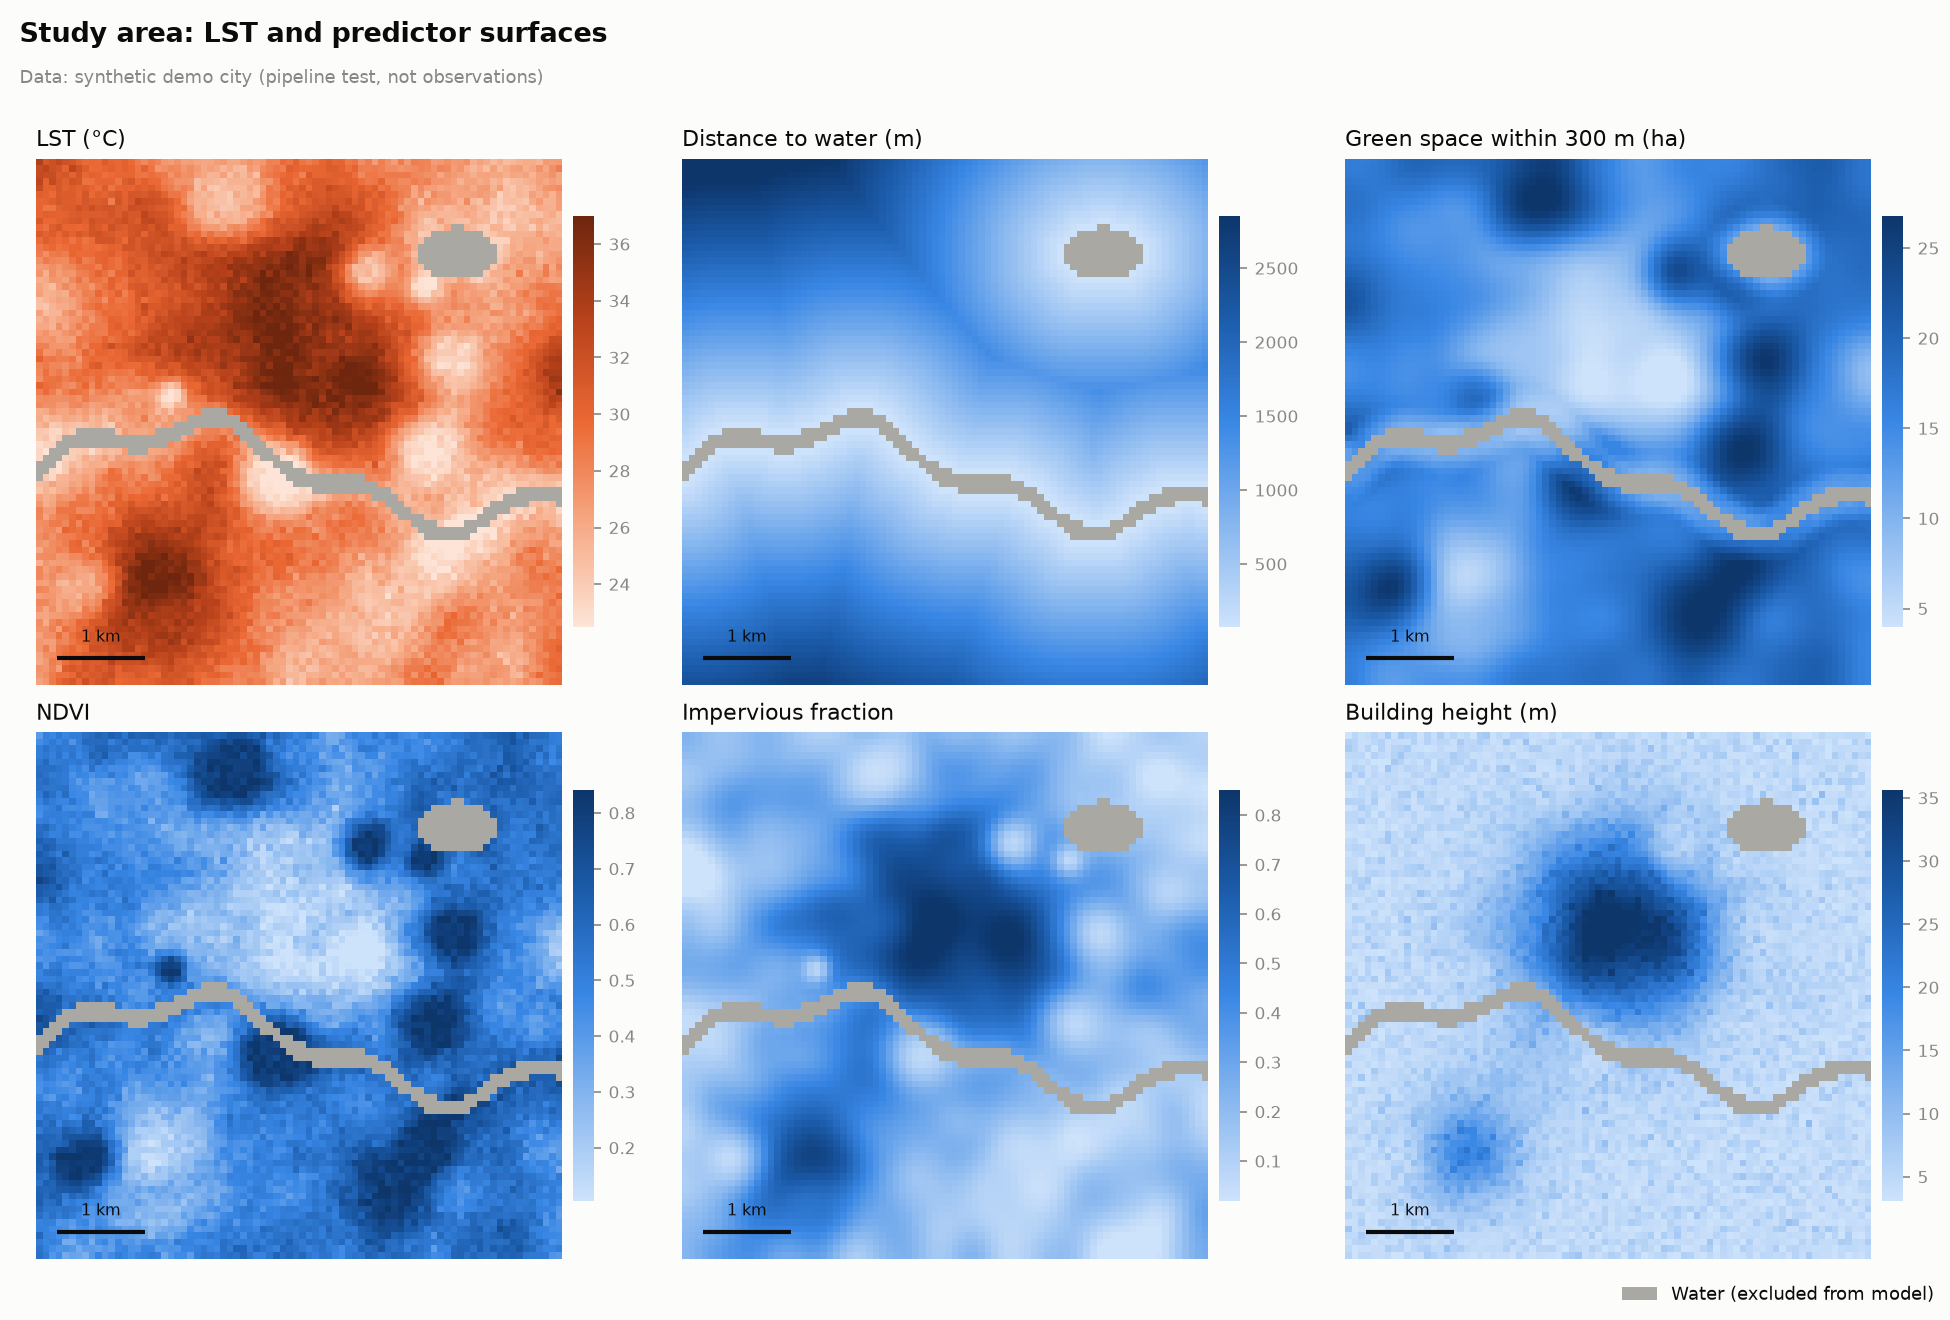

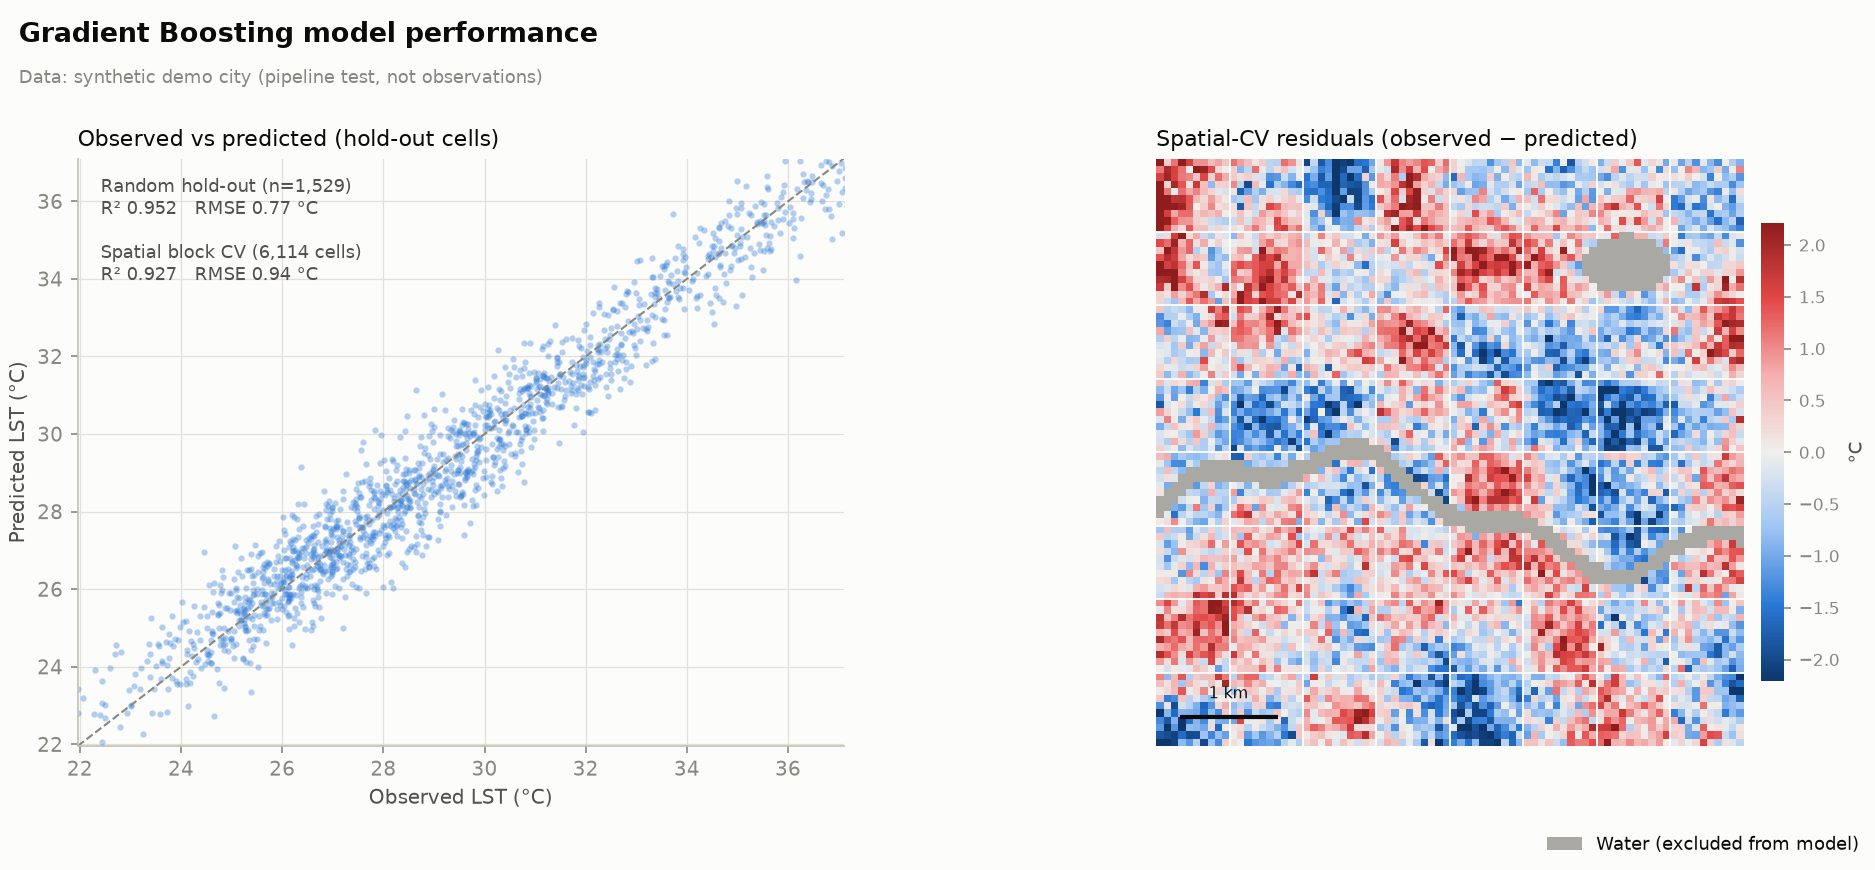

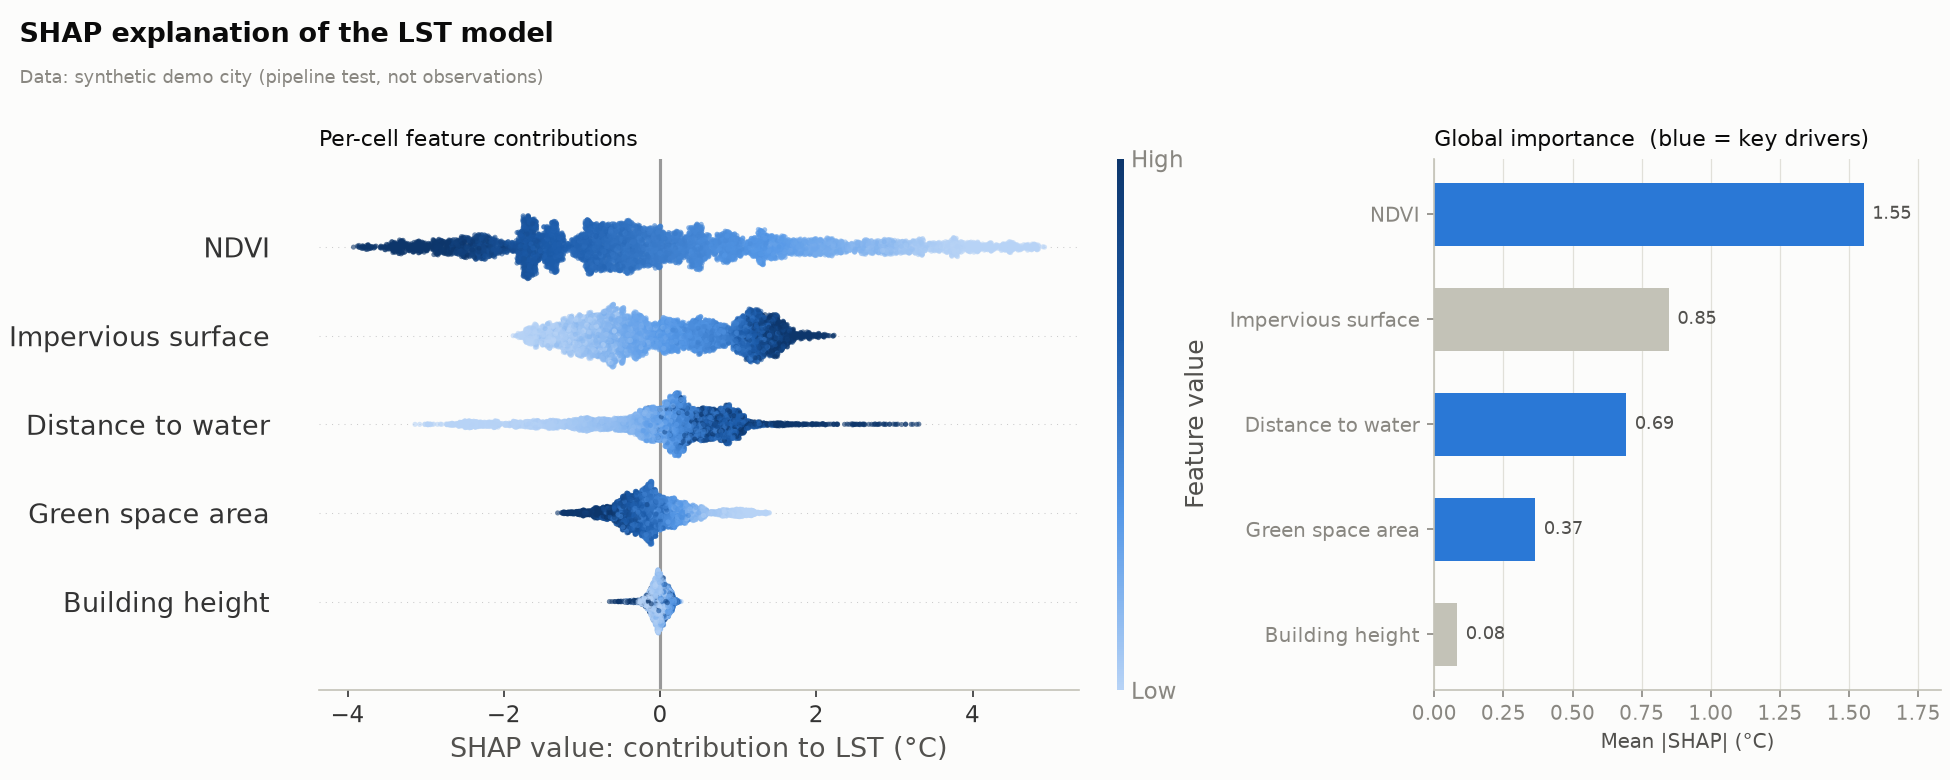

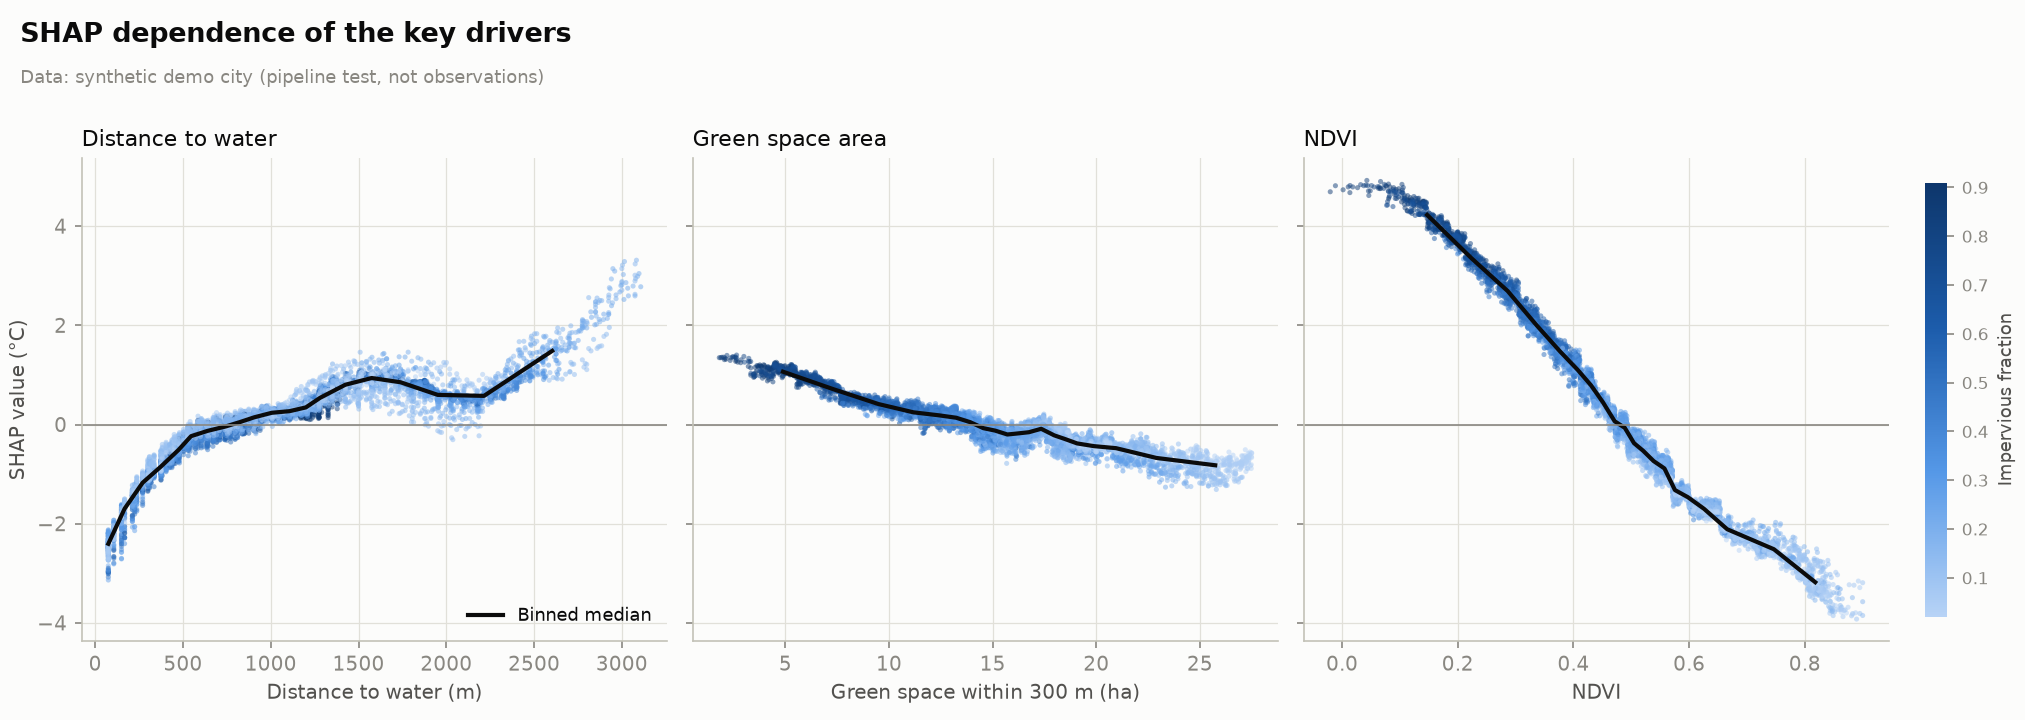

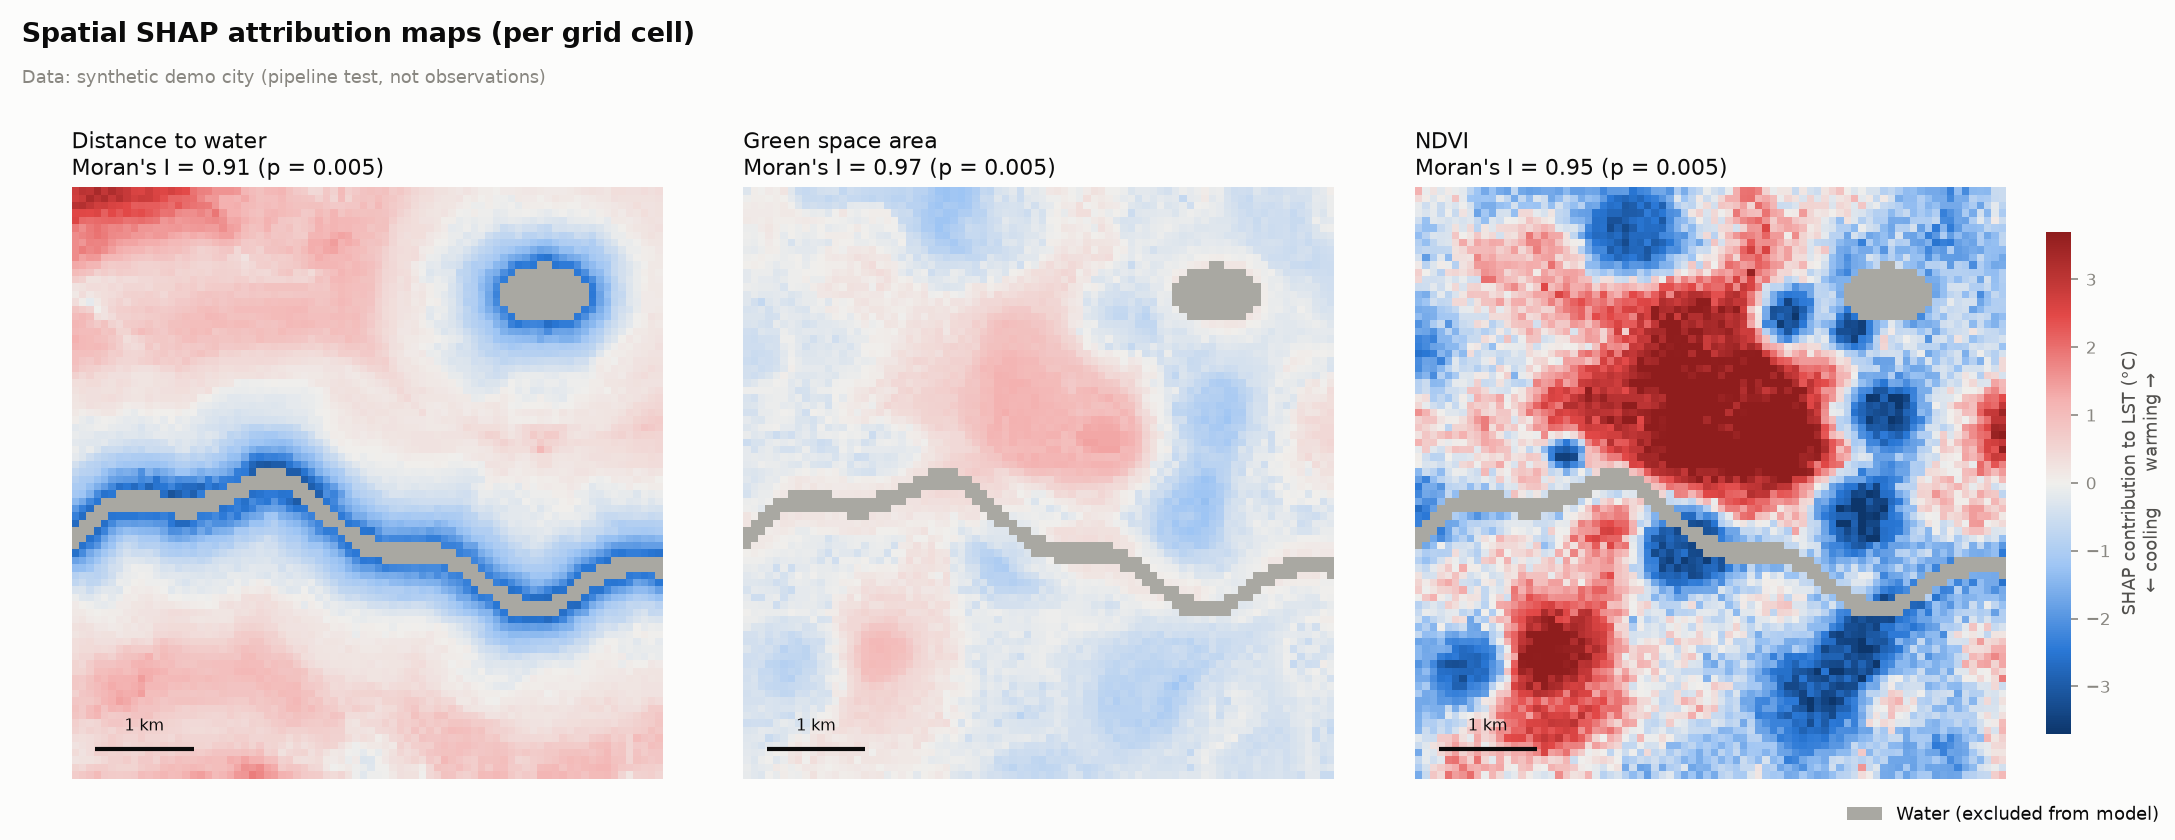

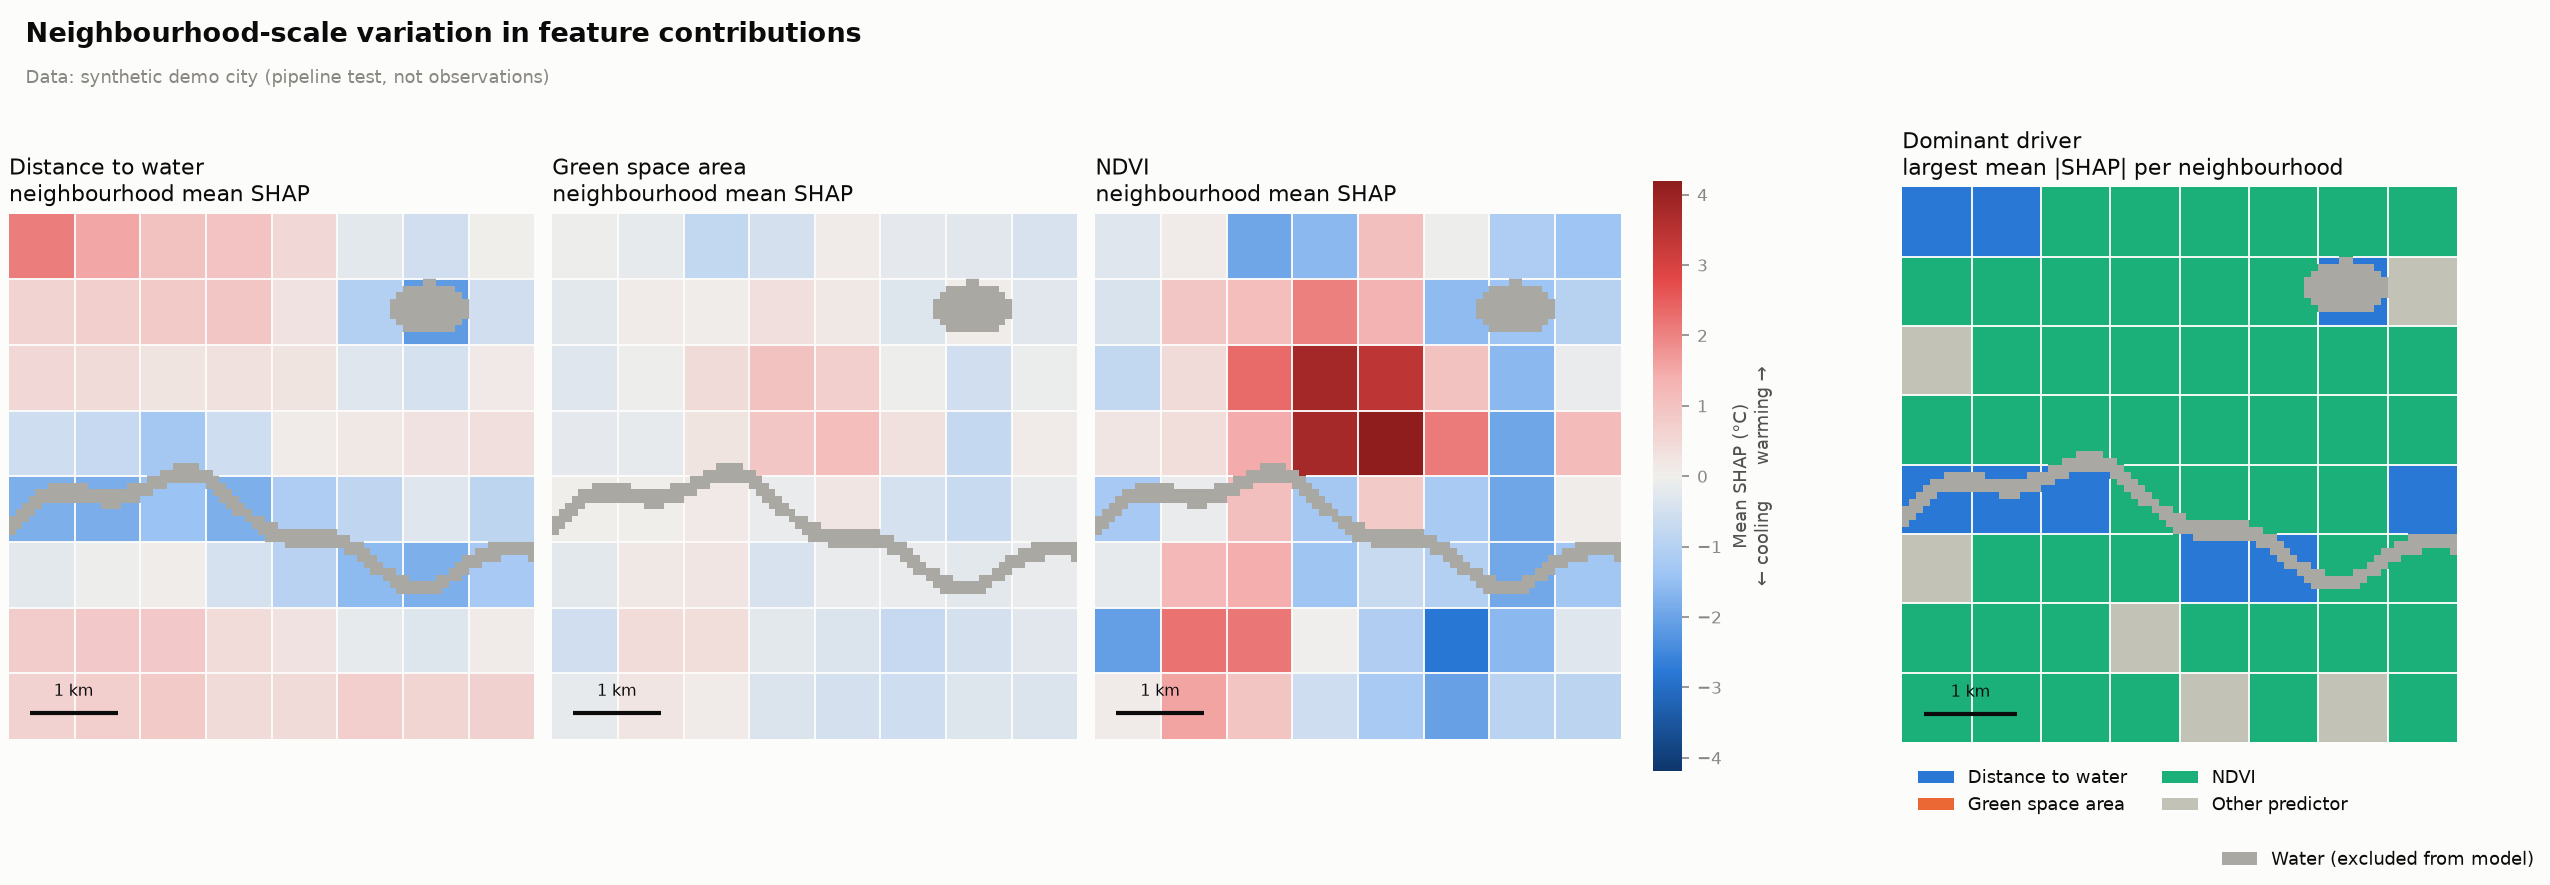

In [2]:
#!/usr/bin/env python3
"""
Explainable GeoAI for urban Land Surface Temperature (LST)
==========================================================

Gradient Boosting regression of LST on urban form and land-cover predictors,
explained with SHAP (TreeExplainer), with per-cell and neighbourhood-scale
SHAP attribution maps.

Pipeline
--------
1. Load a gridded cell table (one row per grid cell), or build a synthetic
   demo city when no data file is given.
2. Fit a GradientBoostingRegressor. Evaluate it on a random hold-out set and
   with spatial block cross-validation (neighbourhoods as CV groups), since
   random splits overstate accuracy on spatially autocorrelated data.
3. Compute exact tree SHAP values for every land cell.
4. Map SHAP values for the key drivers (distance to water, green space area,
   NDVI), aggregate them to neighbourhoods, and test their spatial structure
   with global Moran's I.

Input table (--data)
--------------------
CSV, one row per cell of a regular grid, with columns:
    x, y              cell centre in a projected CRS (metres)
    lst               land surface temperature (deg C)
    dist_water_m      distance to the nearest water body (m)
    green_area_ha     green space area within 300 m of the cell (ha)
    ndvi              mean NDVI of the cell
    impervious_frac   impervious surface fraction (0-1)
    bldg_height_m     mean building height (m)
optional:
    neighborhood      neighbourhood / block-group ID used for aggregation
    is_water          1 for water cells (drawn on maps, excluded from model)

Without --data the script runs on a SYNTHETIC city whose LST comes from a
known generating equation (see make_synthetic_city). Results in that mode
test the pipeline only; they are not empirical findings.

Usage
-----
Command line:
    python lst_shap_prototype.py
    python lst_shap_prototype.py --data data/cells_100m.csv --out outputs --tune

Jupyter / ArcGIS Pro notebook: run the cell as is (demo mode), or call
    main(["--data", r"C:\\path\\to\\cells.csv", "--tune"])

Requirements: numpy, pandas, scipy, scikit-learn, shap, matplotlib
"""

from __future__ import annotations

import argparse
import json
import sys
import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from scipy import ndimage
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict, train_test_split

# --------------------------------------------------------------------------- #
# Configuration
# --------------------------------------------------------------------------- #
TARGET = "lst"
FEATURES = ["dist_water_m", "green_area_ha", "ndvi", "impervious_frac", "bldg_height_m"]
KEY_FEATURES = ["dist_water_m", "green_area_ha", "ndvi"]  # drivers mapped in detail

LABELS = {
    "lst": "LST (°C)",
    "dist_water_m": "Distance to water (m)",
    "green_area_ha": "Green space within 300 m (ha)",
    "ndvi": "NDVI",
    "impervious_frac": "Impervious fraction",
    "bldg_height_m": "Building height (m)",
}
SHORT = {
    "dist_water_m": "Distance to water",
    "green_area_ha": "Green space area",
    "ndvi": "NDVI",
    "impervious_frac": "Impervious surface",
    "bldg_height_m": "Building height",
}


@dataclass
class Config:
    seed: int = 42
    grid_n: int = 80                 # synthetic grid is grid_n x grid_n cells
    cell_m: float = 75.0             # synthetic cell size (m)
    green_radius_m: float = 300.0    # buffer for green space area
    block_m: float = 750.0           # neighbourhood block size if no IDs are given
    test_size: float = 0.25
    cv_folds: int = 5
    n_permutations: int = 199        # Moran's I pseudo p-value
    gbr_params: dict = field(default_factory=lambda: dict(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        min_samples_leaf=15,
        subsample=0.8,
        random_state=42,
    ))


# Colours: sequential = one hue light->dark; diverging = blue/red with grey midpoint.
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRIDLINE, SURFACE, WATER = "#e1e0d9", "#fcfcfb", "#a9a8a2"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
SEQ_HEAT = LinearSegmentedColormap.from_list(
    "seq_heat", ["#fde4d6", "#f6a985", "#eb6834", "#b8421b", "#6e260e"])
SEQ_POINTS = LinearSegmentedColormap.from_list(
    "seq_points", ["#b7d3f6", "#5598e7", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list(
    "div_cool_warm", ["#0d366b", "#2a78d6", "#9ec5f4", "#f0efec", "#f4b1b0", "#e34948", "#8f1d1d"])
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]   # one slot per key feature
OTHER = "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
})


def log(msg: str) -> None:
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


# --------------------------------------------------------------------------- #
# Data
# --------------------------------------------------------------------------- #
def _smooth_noise(rng: np.random.Generator, shape: tuple, sigma: float) -> np.ndarray:
    """Spatially autocorrelated standard-normal field."""
    z = ndimage.gaussian_filter(rng.standard_normal(shape), sigma)
    return (z - z.mean()) / z.std()


def make_synthetic_city(cfg: Config) -> tuple[pd.DataFrame, float]:
    """Build a synthetic gridded city with a river, a lake, parks and two urban cores.

    LST is generated from a known equation with non-linear cooling from water
    and green space, an NDVI effect, an impervious-surface effect and a
    water x imperviousness interaction, plus correlated and white noise.
    """
    rng = np.random.default_rng(cfg.seed)
    n, c = cfg.grid_n, cfg.cell_m
    L = n * c
    cols, rows = np.meshgrid(np.arange(n), np.arange(n))
    X = (cols + 0.5) * c
    Y = (n - rows - 0.5) * c

    def blob(cx, cy, r):
        return np.exp(-((X - cx) ** 2 + (Y - cy) ** 2) / (2 * r ** 2))

    # Water: meandering river + lake
    river_y = 0.40 * L + 0.09 * L * np.sin(X / (0.17 * L)) + 0.025 * L * np.sin(X / (0.045 * L))
    water = np.abs(Y - river_y) < 1.3 * c
    water |= ((X - 0.80 * L) / (0.075 * L)) ** 2 + ((Y - 0.82 * L) / (0.05 * L)) ** 2 < 1
    dist_water = ndimage.distance_transform_edt(~water) * c

    # Urban form: CBD + secondary (industrial) centre, scattered parks, riparian green
    core = np.clip(blob(0.52 * L, 0.62 * L, 0.20 * L) + 0.65 * blob(0.22 * L, 0.20 * L, 0.11 * L), 0, 1)
    parks = np.zeros_like(X)
    for _ in range(10):
        cx, cy = rng.uniform(0.05, 0.95, 2) * L
        parks += blob(cx, cy, rng.uniform(1.5, 4.5) * c)
    parks = np.clip(parks, 0, 1)
    riparian = 0.55 * np.exp(-dist_water / (2.5 * c))

    imperv = 0.12 + 0.80 * core + 0.07 * _smooth_noise(rng, X.shape, 3)
    imperv = np.clip(imperv * (1 - 0.85 * parks) * (1 - 0.6 * riparian), 0.02, 0.97)
    green = np.clip(0.75 * (1 - imperv) + 0.5 * parks + 0.3 * riparian
                    + 0.05 * _smooth_noise(rng, X.shape, 2), 0, 1)
    green[water] = 0.0
    ndvi = np.clip(0.03 + 0.78 * green + 0.035 * rng.standard_normal(X.shape), -0.05, 0.9)

    r_px = cfg.green_radius_m / c
    k = int(np.ceil(r_px))
    yy, xx = np.mgrid[-k:k + 1, -k:k + 1]
    kernel = (xx ** 2 + yy ** 2 <= r_px ** 2).astype(float)
    green_area_ha = ndimage.convolve(green, kernel, mode="reflect") * c * c / 1e4

    bldg_h = np.clip(3 + 40 * core ** 1.8 * imperv + 2.0 * np.abs(rng.standard_normal(X.shape)), 2, 70)

    # Generating equation for LST (deg C)
    lst = (31.0
           + 7.0 * imperv
           - 8.5 * (ndvi - 0.35)
           - 4.5 * np.exp(-dist_water / 350.0) * (1 - 0.4 * imperv)
           - 3.0 * (1 - np.exp(-green_area_ha / 12.0))
           - 0.03 * bldg_h * imperv
           + 0.8 * _smooth_noise(rng, X.shape, 5)
           + 0.5 * rng.standard_normal(X.shape))

    x0, y0 = 500_000.0, 4_300_000.0  # arbitrary projected origin (m)
    df = pd.DataFrame({
        "row": rows.ravel(), "col": cols.ravel(),
        "x": x0 + X.ravel(), "y": y0 + Y.ravel(),
        "is_water": water.ravel(),
        "dist_water_m": dist_water.ravel(),
        "green_area_ha": green_area_ha.ravel(),
        "ndvi": ndvi.ravel(),
        "impervious_frac": imperv.ravel(),
        "bldg_height_m": bldg_h.ravel(),
        TARGET: lst.ravel(),
    })
    return df, c


def load_cell_table(path: Path) -> tuple[pd.DataFrame, float]:
    """Read a gridded cell table and recover row/col indices from x/y."""
    df = pd.read_csv(path)
    missing = {"x", "y", TARGET, *FEATURES} - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")
    df["is_water"] = df.get("is_water", 0).astype(bool)
    xs = np.sort(df["x"].unique())
    cell = float(np.median(np.diff(xs)))
    df["col"] = np.rint((df["x"] - df["x"].min()) / cell).astype(int)
    df["row"] = np.rint((df["y"].max() - df["y"]) / cell).astype(int)
    return df, cell


def assign_neighborhoods(df: pd.DataFrame, block_m: float) -> pd.DataFrame:
    """Use supplied neighbourhood IDs, or fall back to square blocks of block_m."""
    if "neighborhood" in df.columns:
        df["neighborhood"] = df["neighborhood"].astype(str)
        return df
    bx = ((df["x"] - df["x"].min()) // block_m).astype(int)
    by = ((df["y"].max() - df["y"]) // block_m).astype(int)
    df["neighborhood"] = "NB-" + by.map("{:02d}".format) + "-" + bx.map("{:02d}".format)
    return df


def to_grid(rows: np.ndarray, cols: np.ndarray, values: np.ndarray, shape: tuple) -> np.ndarray:
    g = np.full(shape, np.nan)
    g[rows, cols] = values
    return g


# --------------------------------------------------------------------------- #
# Modelling
# --------------------------------------------------------------------------- #
def tune_hyperparameters(X: pd.DataFrame, y: pd.Series, groups: pd.Series, cfg: Config) -> dict:
    """Small grid search with spatial (grouped) folds."""
    grid = {"max_depth": [3, 4, 5], "learning_rate": [0.03, 0.05, 0.1], "min_samples_leaf": [10, 25]}
    base = {k: v for k, v in cfg.gbr_params.items() if k not in grid}
    search = GridSearchCV(GradientBoostingRegressor(**base), grid,
                          cv=GroupKFold(n_splits=3), scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y, groups=groups)
    log(f"  best params {search.best_params_}  (spatial-CV RMSE {-search.best_score_:.2f} °C)")
    return {**base, **search.best_params_}


def metrics(y_true, y_pred) -> dict:
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
    }


def fit_and_evaluate(land: pd.DataFrame, cfg: Config, tune: bool):
    X, y, groups = land[FEATURES], land[TARGET], land["neighborhood"]
    X_tr, X_te, y_tr, y_te, g_tr, _ = train_test_split(
        X, y, groups, test_size=cfg.test_size, random_state=cfg.seed)

    params = tune_hyperparameters(X_tr, y_tr, g_tr, cfg) if tune else dict(cfg.gbr_params)
    model = GradientBoostingRegressor(**params).fit(X_tr, y_tr)

    results = {
        "params": params,
        "n_train": int(len(X_tr)), "n_test": int(len(X_te)),
        "train": metrics(y_tr, model.predict(X_tr)),
        "test_random": metrics(y_te, model.predict(X_te)),
    }

    # Spatial block CV: whole neighbourhoods held out together
    oof = cross_val_predict(GradientBoostingRegressor(**params), X, y,
                            groups=groups, cv=GroupKFold(n_splits=cfg.cv_folds))
    results["cv_spatial"] = metrics(y, oof)
    test_idx = X_te.index
    return model, results, oof, test_idx


def compute_shap(model, X: pd.DataFrame) -> tuple[shap.Explanation, float]:
    explainer = shap.TreeExplainer(model)
    exp = explainer(X)
    base = float(np.ravel(explainer.expected_value)[0])
    gap = np.abs(base + exp.values.sum(axis=1) - model.predict(X)).max()
    log(f"  SHAP additivity check: max |base + sum(SHAP) - prediction| = {gap:.2e} °C")
    return exp, base


# --------------------------------------------------------------------------- #
# Spatial statistics
# --------------------------------------------------------------------------- #
def _rook_cross(z: np.ndarray) -> tuple[float, int]:
    """Sum of z_i*z_j over rook-adjacent valid pairs (each pair counted twice), and weight total."""
    num, w = 0.0, 0
    for a, b in ((z[:, :-1], z[:, 1:]), (z[:-1, :], z[1:, :])):
        m = ~np.isnan(a) & ~np.isnan(b)
        num += 2 * float(np.sum(a[m] * b[m]))
        w += 2 * int(m.sum())
    return num, w


def morans_i(grid: np.ndarray, n_perm: int, rng: np.random.Generator) -> tuple[float, float]:
    """Global Moran's I with rook contiguity and a permutation pseudo p-value."""
    valid = ~np.isnan(grid)
    vals = grid[valid]

    def stat(v):
        z = np.full(grid.shape, np.nan)
        z[valid] = v - v.mean()
        num, w = _rook_cross(z)
        return (len(v) / w) * num / float(np.sum((v - v.mean()) ** 2))

    obs = stat(vals)
    perms = np.array([stat(rng.permutation(vals)) for _ in range(n_perm)])
    p = (np.sum(perms >= obs) + 1) / (n_perm + 1)
    return float(obs), float(p)


# --------------------------------------------------------------------------- #
# Plotting
# --------------------------------------------------------------------------- #
class MapCanvas:
    """Shared geometry for drawing grids as maps in local km coordinates."""

    def __init__(self, shape: tuple, cell_m: float, water: np.ndarray, nb_codes: np.ndarray):
        self.shape = shape
        self.cell_km = cell_m / 1000
        self.H, self.W = shape[0] * self.cell_km, shape[1] * self.cell_km
        self.extent = [0, self.W, 0, self.H]
        self.water = np.where(water, 1.0, np.nan)
        self.nb_segments = self._edges(nb_codes)

    def _edges(self, codes: np.ndarray) -> list:
        ck, H = self.cell_km, self.H
        segs = []
        v = (codes[:, :-1] != codes[:, 1:]) & (codes[:, :-1] >= 0) & (codes[:, 1:] >= 0)
        for r, c in zip(*np.nonzero(v)):
            x = (c + 1) * ck
            segs.append([(x, H - (r + 1) * ck), (x, H - r * ck)])
        h = (codes[:-1, :] != codes[1:, :]) & (codes[:-1, :] >= 0) & (codes[1:, :] >= 0)
        for r, c in zip(*np.nonzero(h)):
            y = H - (r + 1) * ck
            segs.append([(c * ck, y), ((c + 1) * ck, y)])
        return segs

    def draw(self, ax, grid, title, cmap, norm=None, vmin=None, vmax=None,
             nb_lines=False, cbar_label=None, fig=None):
        im = ax.imshow(grid, extent=self.extent, cmap=cmap, norm=norm, vmin=vmin, vmax=vmax,
                       interpolation="nearest")
        ax.imshow(self.water, extent=self.extent, cmap=ListedColormap([WATER]), interpolation="nearest")
        if nb_lines:
            ax.add_collection(LineCollection(self.nb_segments, colors=SURFACE, linewidths=0.9))
        ax.set_title(title, loc="left", fontsize=10.5, color=INK, pad=6)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        self._scalebar(ax)
        if fig is not None and cbar_label is not None:
            cb = fig.colorbar(im, ax=ax, shrink=0.78, pad=0.02)
            cb.outline.set_visible(False)
            cb.ax.tick_params(labelsize=8, color=MUTED)
            cb.set_label(cbar_label, color=INK2, fontsize=8.5)
        return im

    def _scalebar(self, ax, km=1.0):
        x0, y0 = 0.04 * self.W, 0.05 * self.H
        ax.plot([x0, x0 + km], [y0, y0], color=INK, lw=2, solid_capstyle="butt")
        ax.text(x0 + km / 2, y0 + 0.025 * self.H, f"{km:g} km", ha="center", va="bottom",
                fontsize=7.5, color=INK)


def new_figure(figsize, title, source, top_in=0.75, bottom_in=0.35):
    """Figure with constrained layout, a header band (title + data source) and a footer band."""
    fig = plt.figure(figsize=figsize, layout="constrained")
    h = figsize[1]
    b, t = bottom_in / h, (top_in + 0.05) / h
    fig.get_layout_engine().set(rect=(0, b, 1, 1 - b - t), h_pad=0.06, w_pad=0.06)  # (l, b, w, h)
    fig.text(0.01, 1 - 0.14 / h, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.01, 1 - 0.46 / h, f"Data: {source}", ha="left", va="top", fontsize=8.5, color=MUTED)
    return fig


def _water_legend(fig):
    fig.legend(handles=[Patch(facecolor=WATER, label="Water (excluded from model)")],
               loc="lower right", frameon=False, fontsize=8.5)


def _colorbar(fig, im, ax, label, shrink=0.8):
    cb = fig.colorbar(im, ax=ax, shrink=shrink, pad=0.02)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8, color=MUTED)
    cb.set_label(label, color=INK2, fontsize=8.5)
    return cb


def fig_inputs(canvas, grids, source, out):
    fig = new_figure((13, 8.8), "Study area: LST and predictor surfaces", source)
    axes = fig.subplots(2, 3)
    panels = [(TARGET, SEQ_HEAT)] + [(f, SEQ_BLUE) for f in FEATURES]
    for ax, (name, cmap) in zip(axes.ravel(), panels):
        g = grids[name]
        canvas.draw(ax, g, LABELS[name], cmap, vmin=np.nanpercentile(g, 1),
                    vmax=np.nanpercentile(g, 99), cbar_label="", fig=fig)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_performance(land, model, test_idx, oof, res, canvas, source, out):
    fig = new_figure((12.5, 5.8), "Gradient Boosting model performance", source)
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.15]})
    y_te = land.loc[test_idx, TARGET]
    p_te = model.predict(land.loc[test_idx, FEATURES])
    lo, hi = np.percentile(np.r_[y_te, p_te], [0.5, 99.5])
    ax1.scatter(y_te, p_te, s=9, color="#2a78d6", alpha=0.35, linewidths=0)
    ax1.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls="--")
    ax1.set_xlim(lo, hi); ax1.set_ylim(lo, hi)
    ax1.set_xlabel("Observed LST (°C)"); ax1.set_ylabel("Predicted LST (°C)")
    ax1.grid(color=GRIDLINE, lw=0.6); ax1.set_axisbelow(True)
    t, s = res["test_random"], res["cv_spatial"]
    ax1.text(0.03, 0.97,
             f"Random hold-out (n={res['n_test']:,})\nR² {t['r2']:.3f}   RMSE {t['rmse']:.2f} °C\n\n"
             f"Spatial block CV ({len(land):,} cells)\nR² {s['r2']:.3f}   RMSE {s['rmse']:.2f} °C",
             transform=ax1.transAxes, va="top", fontsize=8.8, color=INK2)
    ax1.set_title("Observed vs predicted (hold-out cells)", loc="left", fontsize=10.5)

    resid = to_grid(land["row"].values, land["col"].values, land[TARGET].values - oof, canvas.shape)
    m = np.nanpercentile(np.abs(resid), 98)
    canvas.draw(ax2, resid, "Spatial-CV residuals (observed − predicted)", DIVERGING,
                norm=TwoSlopeNorm(0, -m, m), nb_lines=True, cbar_label="°C", fig=fig)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_shap_summary(exp, importance, source, out):
    fig = new_figure((13, 5.2), "SHAP explanation of the LST model", source, bottom_in=0.05)
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1.5, 1]})
    exp_named = shap.Explanation(exp.values, exp.base_values, exp.data,
                                 feature_names=[SHORT[f] for f in FEATURES])
    shap.plots.beeswarm(exp_named, ax=ax1, show=False, plot_size=None, color=SEQ_POINTS, s=6, alpha=0.6)
    ax1.set_xlabel("SHAP value: contribution to LST (°C)")
    ax1.set_title("Per-cell feature contributions", loc="left", fontsize=10.5)

    imp = importance.sort_values()
    colors = ["#2a78d6" if f in KEY_FEATURES else OTHER for f in imp.index]
    ax2.barh([SHORT[f] for f in imp.index], imp.values, color=colors, height=0.6)
    for i, v in enumerate(imp.values):
        ax2.text(v + imp.max() * 0.02, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
    ax2.set_xlabel("Mean |SHAP| (°C)")
    ax2.set_xlim(0, imp.max() * 1.18)
    ax2.grid(axis="x", color=GRIDLINE, lw=0.6); ax2.set_axisbelow(True)
    ax2.set_title("Global importance  (blue = key drivers)", loc="left", fontsize=10.5)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_dependence(land, shap_df, source, out):
    fig = new_figure((13.5, 4.8), "SHAP dependence of the key drivers", source, bottom_in=0.05)
    axes = fig.subplots(1, 3, sharey=True)
    for ax, f in zip(axes, KEY_FEATURES):
        x, s = land[f].values, shap_df[f].values
        sc = ax.scatter(x, s, c=land["impervious_frac"], cmap=SEQ_POINTS, s=6, alpha=0.5, linewidths=0)
        bins = np.unique(np.nanpercentile(x, np.linspace(0, 100, 21)))
        idx = np.clip(np.digitize(x, bins) - 1, 0, len(bins) - 2)
        centers = [np.median(x[idx == b]) for b in range(len(bins) - 1) if np.any(idx == b)]
        meds = [np.median(s[idx == b]) for b in range(len(bins) - 1) if np.any(idx == b)]
        ax.plot(centers, meds, color=INK, lw=2, label="Binned median")
        ax.axhline(0, color=MUTED, lw=0.8)
        ax.set_xlabel(LABELS[f])
        ax.grid(color=GRIDLINE, lw=0.6); ax.set_axisbelow(True)
        ax.set_title(SHORT[f], loc="left", fontsize=10.5)
    axes[0].set_ylabel("SHAP value (°C)")
    axes[0].legend(frameon=False, fontsize=8.5, loc="lower right")
    cb = _colorbar(fig, sc, axes, "Impervious fraction", shrink=0.9)
    cb.solids.set_alpha(1)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_spatial_shap(canvas, shap_grids, moran, source, out):
    fig = new_figure((14.5, 5.6), "Spatial SHAP attribution maps (per grid cell)", source)
    axes = fig.subplots(1, 3)
    m = np.nanpercentile(np.abs(np.stack([shap_grids[f] for f in KEY_FEATURES])), 98)
    norm = TwoSlopeNorm(0, -m, m)
    for ax, f in zip(axes, KEY_FEATURES):
        I, p = moran[f]
        im = canvas.draw(ax, shap_grids[f], f"{SHORT[f]}\nMoran's I = {I:.2f} (p = {p:.3f})",
                         DIVERGING, norm=norm)
    _colorbar(fig, im, axes, "SHAP contribution to LST (°C)\n← cooling      warming →", shrink=0.85)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_neighborhood(canvas, land, nb_table, source, out):
    fig = new_figure((17, 5.9), "Neighbourhood-scale variation in feature contributions", source)
    left, right = fig.subfigures(1, 2, width_ratios=[3.25, 1.35], wspace=0.02)
    axes = left.subplots(1, 3)
    rows, cols = land["row"].values, land["col"].values
    nb_of_cell = land["neighborhood"].values
    m = np.abs(nb_table[[f"shap_{f}" for f in KEY_FEATURES]].values).max()
    norm = TwoSlopeNorm(0, -m, m)
    for ax, f in zip(axes, KEY_FEATURES):
        vals = nb_table[f"shap_{f}"].reindex(nb_of_cell).values
        im = canvas.draw(ax, to_grid(rows, cols, vals, canvas.shape),
                         f"{SHORT[f]}\nneighbourhood mean SHAP", DIVERGING, norm=norm, nb_lines=True)
    _colorbar(left, im, axes, "Mean SHAP (°C)\n← cooling      warming →", shrink=0.85)

    ax = right.subplots()
    order = KEY_FEATURES + ["other"]
    code = nb_table["dominant_driver"].map(lambda d: order.index(d) if d in order else 3)
    dom = to_grid(rows, cols, code.reindex(nb_of_cell).values, canvas.shape)
    canvas.draw(ax, dom, "Dominant driver\nlargest mean |SHAP| per neighbourhood",
                ListedColormap(CATEGORICAL + [OTHER]), vmin=-0.5, vmax=3.5, nb_lines=True)
    handles = [Patch(facecolor=CATEGORICAL[i], label=SHORT[f]) for i, f in enumerate(KEY_FEATURES)]
    handles.append(Patch(facecolor=OTHER, label="Other predictor"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.02), ncol=2,
              frameon=False, fontsize=8.5)
    _water_legend(fig)
    fig.savefig(out, dpi=150)
    plt.close(fig)


# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #
def _in_notebook() -> bool:
    """True inside a Jupyter / ArcGIS Pro notebook kernel."""
    try:
        from IPython import get_ipython
        ip = get_ipython()
        return ip is not None and "IPKernelApp" in ip.config
    except Exception:
        return False


def main(argv: list[str] | None = None):
    ap = argparse.ArgumentParser(
        description="Explainable GeoAI for urban LST: Gradient Boosting + SHAP attribution maps")
    ap.add_argument("--data", type=Path, help="gridded cell table (CSV); omit for synthetic demo city")
    ap.add_argument("--out", type=Path, default=Path("outputs"), help="output folder")
    ap.add_argument("--tune", action="store_true", help="grid-search GBR hyperparameters (spatial CV)")
    ap.add_argument("--seed", type=int, default=42)
    if argv is None:
        # A notebook kernel puts its own flags (-f kernel-....json) in sys.argv; don't parse those.
        argv = [] if _in_notebook() else sys.argv[1:]
    args = ap.parse_args(argv)

    cfg = Config(seed=args.seed)
    cfg.gbr_params["random_state"] = args.seed
    out = args.out
    out.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(cfg.seed)

    # 1. Data ---------------------------------------------------------------
    if args.data:
        log(f"Loading cell table {args.data}")
        df, cell_m = load_cell_table(args.data)
        source = args.data.name
    else:
        log("No --data given: building synthetic demo city")
        df, cell_m = make_synthetic_city(cfg)
        source = "synthetic demo city (pipeline test, not observations)"
    df = assign_neighborhoods(df, cfg.block_m)
    shape = (int(df["row"].max()) + 1, int(df["col"].max()) + 1)
    land = df.loc[~df["is_water"]].dropna(subset=FEATURES + [TARGET]).copy()
    log(f"  grid {shape[0]}x{shape[1]} @ {cell_m:g} m | {len(land):,} land cells | "
        f"{land['neighborhood'].nunique()} neighbourhoods")

    # 2. Model --------------------------------------------------------------
    log("Fitting Gradient Boosting regressor" + (" with spatial-CV tuning" if args.tune else ""))
    model, res, oof, test_idx = fit_and_evaluate(land, cfg, args.tune)
    for k in ("train", "test_random", "cv_spatial"):
        r = res[k]
        log(f"  {k:<12} R² {r['r2']:.3f} | RMSE {r['rmse']:.2f} °C | MAE {r['mae']:.2f} °C")

    # 3. SHAP ---------------------------------------------------------------
    log("Computing TreeSHAP values for all land cells")
    exp, base = compute_shap(model, land[FEATURES])
    shap_df = pd.DataFrame(exp.values, columns=FEATURES, index=land.index)
    importance = shap_df.abs().mean().sort_values(ascending=False)
    log("  mean |SHAP| (°C): " + ", ".join(f"{SHORT[f]} {v:.2f}" for f, v in importance.items()))

    # 4. Spatial attribution -----------------------------------------------
    rows, cols = land["row"].values, land["col"].values
    grids = {name: to_grid(rows, cols, land[name].values, shape) for name in FEATURES + [TARGET]}
    shap_grids = {f: to_grid(rows, cols, shap_df[f].values, shape) for f in FEATURES}

    log(f"Global Moran's I of SHAP maps ({cfg.n_permutations} permutations)")
    moran = {f: morans_i(shap_grids[f], cfg.n_permutations, rng) for f in FEATURES}
    for f, (I, p) in moran.items():
        log(f"  {SHORT[f]:<20} I = {I:.3f}  p = {p:.3f}")

    nb = land[["neighborhood", TARGET]].join(shap_df.add_prefix("shap_"))
    nb_table = nb.groupby("neighborhood").agg(
        n_cells=(TARGET, "size"), mean_lst=(TARGET, "mean"),
        **{f"shap_{f}": (f"shap_{f}", "mean") for f in FEATURES})
    abs_mean = land[["neighborhood"]].join(shap_df.abs()).groupby("neighborhood").mean()
    dominant = abs_mean.idxmax(axis=1)
    nb_table["dominant_driver"] = dominant.where(dominant.isin(KEY_FEATURES), "other")
    nb_table = nb_table[nb_table["n_cells"] >= 5]

    hot = nb_table.sort_values("mean_lst", ascending=False).head(5)
    log("Hottest neighbourhoods (mean LST, contributions in °C):")
    for name, r in hot.iterrows():
        parts = ", ".join(f"{SHORT[f]} {r[f'shap_{f}']:+.2f}" for f in KEY_FEATURES)
        log(f"  {name}  {r['mean_lst']:.1f} °C | {parts}")

    # 5. Outputs ------------------------------------------------------------
    log(f"Writing figures and tables to {out}/")
    codes = pd.Series(pd.factorize(land["neighborhood"])[0], index=land.index)
    nb_codes = to_grid(rows, cols, codes.values, shape)
    nb_codes = np.where(np.isnan(nb_codes), -1, nb_codes).astype(int)
    water = np.zeros(shape, bool)
    w = df.loc[df["is_water"]]
    water[w["row"].values, w["col"].values] = True
    canvas = MapCanvas(shape, cell_m, water, nb_codes)

    fig_inputs(canvas, grids, source, out / "fig1_study_area_inputs.png")
    fig_performance(land, model, test_idx, oof, res, canvas, source, out / "fig2_model_performance.png")
    fig_shap_summary(exp, importance, source, out / "fig3_shap_summary.png")
    fig_dependence(land, shap_df, source, out / "fig4_shap_dependence.png")
    fig_spatial_shap(canvas, shap_grids, moran, source, out / "fig5_spatial_shap_maps.png")
    fig_neighborhood(canvas, land, nb_table, source, out / "fig6_neighborhood_shap.png")

    land[["x", "y", "neighborhood", TARGET]].assign(
        lst_pred=model.predict(land[FEATURES]), lst_pred_spatial_cv=oof
    ).join(shap_df.add_prefix("shap_")).to_csv(out / "cell_shap_values.csv", index=False)
    nb_table.round(4).to_csv(out / "neighborhood_shap_summary.csv")
    summary = {
        "data_source": source,
        "n_land_cells": int(len(land)),
        "cell_size_m": cell_m,
        "shap_base_value_c": base,
        "model": res,
        "mean_abs_shap_c": importance.round(4).to_dict(),
        "morans_i": {f: {"I": round(I, 4), "p": round(p, 4)} for f, (I, p) in moran.items()},
    }
    (out / "run_summary.json").write_text(json.dumps(summary, indent=2))
    log(f"Done. Outputs in {out.resolve()}")

    if _in_notebook():  # show the saved figures inline
        from IPython.display import Image, display
        for png in sorted(out.glob("fig*.png")):
            display(Image(filename=str(png)))


if __name__ == "__main__":
    main()